In [94]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce
from scipy import linalg as la
from myfunctions import sigma_op, sigma_x,sigma_y, sigma_z, coffs, H_XY, U_trotter, time_evolv, H_isingall
import os

In [95]:
np.arange(5, 21).astype(int)

array([ 5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])

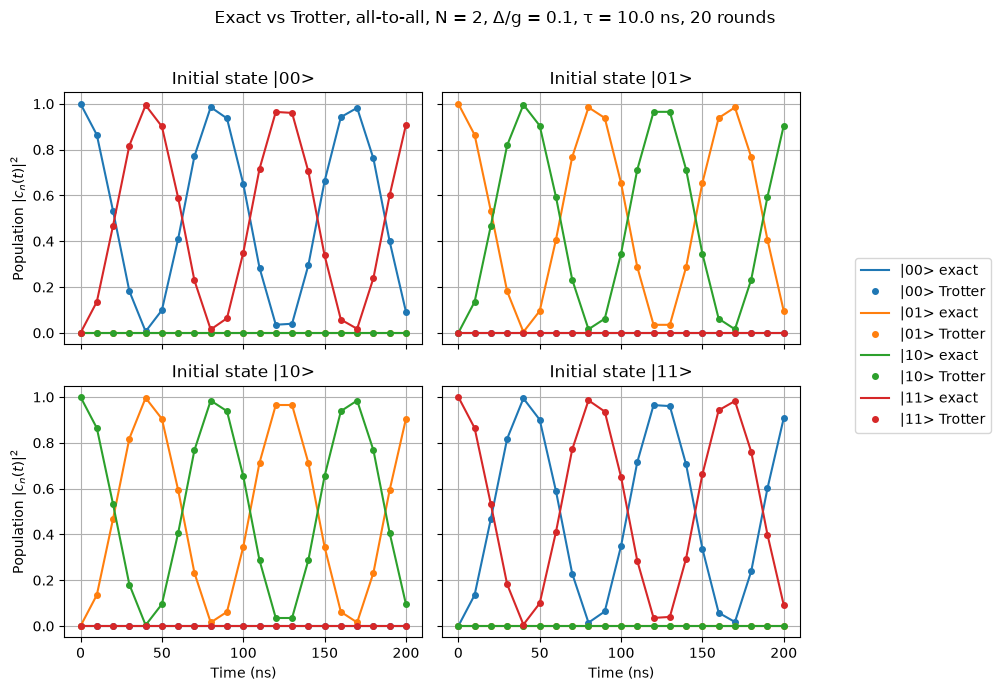

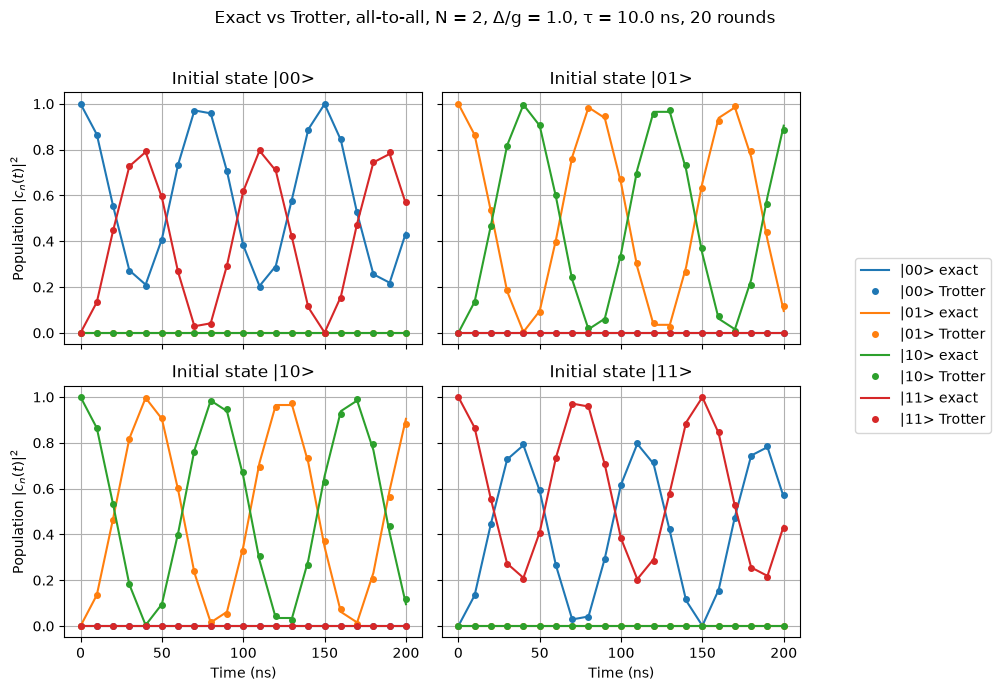

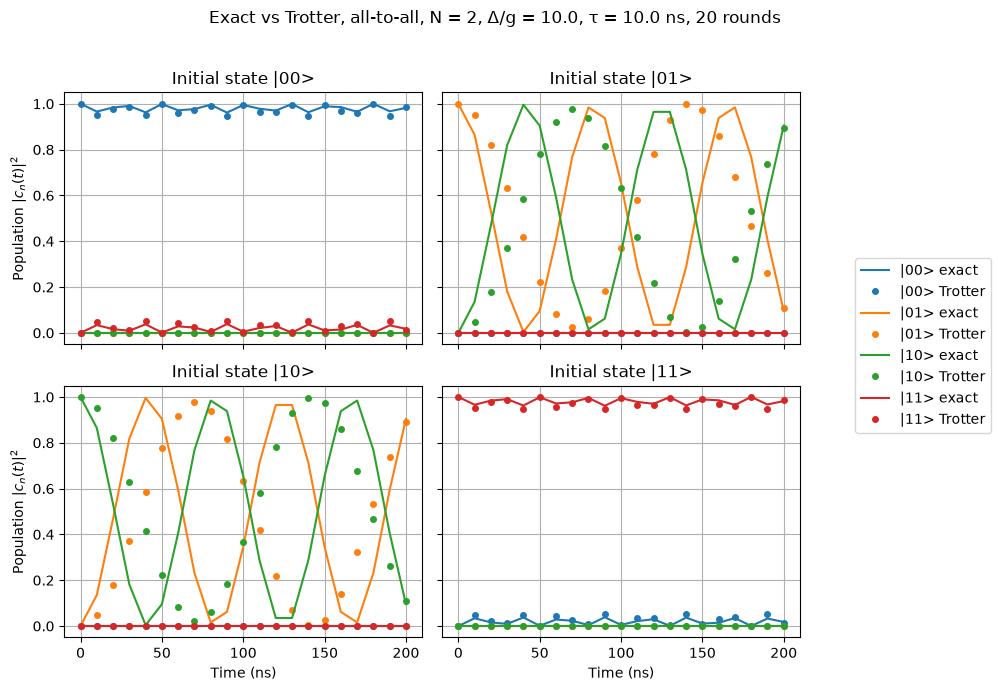

In [96]:
# System parameters for 2 qubits H__ising(units: rad/μs and μs)
N = 2 # number of qubits
c = 2*np.pi * 3                          # coupling, 3 MHz
g = c * (np.ones((N, N)))    # all-to-all, zero diagonal
delta_j_values = np.array([0.1, 1, 10]) * c # so that delta/g = 0.1, 1, 10
t = np.linspace(0, 0.2, 1000)            # μs 0 to 200 ns, 1000 points
# system parameters for 2 qubits trotter
n=20 # number of steps for trotterization
tau = t[-1]/n # step size for trotterization 
g_t= g # coupling for trotterization, same as exact
delta_tj_values = 1/2*delta_j_values # half the Ising field for trotterization

# Computational basis states |00>, |01>, |10>, |11>
basis = np.eye(2**N, dtype=complex) 
n_states = 2**N
t_trotter = tau * np.arange(n + 1)        # times after each Trotter round
t_exact = np.linspace(0, n*tau, 1000)     # same time window, finer grid

ncols = 2 # number of columns for subplots
nrows = int(np.ceil(n_states / ncols)) # number of rows for subplots

for d in delta_j_values:                  # d = Delta^I (Ising field)
    # Exact Ising model
    H_exact = H_isingall(N, d*np.ones(N), g)
    E, V = la.eigh(H_exact)

    # Trotter: gate parameters Delta_j1 = Delta^I / 2
    H_gate = H_XY(N, (d/2)*np.ones(N), g_t)
    U_round = U_trotter(H_gate, tau, 1, N)

    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3.5*nrows),
                             sharex=True, sharey=True)
    axes = axes.flatten()

    for i in range(n_states):
        # Exact evolution
        psi_exact = time_evolv(coffs(V, basis[:, i]), E, V, t_trotter)

        # Trotter evolution, one round at a time
        psi = basis[:, i].copy()
        psi_trot = [psi]
        for step in range(n):
            psi = U_round @ psi
            psi_trot.append(psi)
        psi_trot = np.array(psi_trot)

        ax = axes[i]
        for j in range(n_states):
            color = f'C{j}'
            ax.plot(t_trotter*1e3, np.abs(psi_exact[:, j])**2, '-', color=color,
                    label=f'|{j:0{N}b}> exact')
            ax.plot(t_trotter*1e3, np.abs(psi_trot[:, j])**2, 'o', color=color,
                    markersize=4, label=f'|{j:0{N}b}> Trotter')
        ax.set_title(f'Initial state |{i:0{N}b}>')
        ax.grid()

    for ax in axes[-ncols:]:
        ax.set_xlabel('Time (ns)')
    for ax in axes[::ncols]:
        ax.set_ylabel(r'Population $|c_n(t)|^2$')

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center right')
    ratio = d / g[0, 1]
    fig.suptitle(f'Exact vs Trotter, all-to-all, N = {N}, Δ/g = {ratio:.1f}, '
                 f'τ = {tau*1e3:.1f} ns, {n} rounds')
    fig.tight_layout(rect=[0, 0, 0.82, 0.96])
    plt.show()

In [97]:
psi_exact.shape

(21, 4)

In [98]:
psi_trot.shape

(21, 4)

In [99]:
A =np.array([[1,2,3], [0,1,2]])
B = np.array([[1,2,3], [0,1,2]])

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg as la
from myfunctions import coffs, H_XY, U_trotter, H_isingall, time_evolv


# System parameters for 2 qubits H__ising(units: rad/μs and μs)
N = 2 # number of qubits
c = 2*np.pi * 3                          # coupling, 3 MHz
g = c * (np.ones((N, N)))    # all-to-all, zero diagonal
delta_j_values = np.array([0.1, 1, 10]) * c # so that delta/g = 0.1, 1, 10
t = np.linspace(0, 0.2, 1000)            # μs 0 to 200 ns, 1000 points
# system parameters for 2 qubits trotter
n_steps=np.arange(4, 21).astype(int) # number of steps for trotterization 10ns time step to 50ns time step
g_t= g # coupling for trotterization, same as exact
delta_tj_values = 1/2*delta_j_values # half the Ising field for trotterization

# Computational basis states |00>, |01>, |10>, |11>
ground_state = np.array([1, 0, 0, 0], dtype=complex) # |00>
overlap = {} # dictionary to store overlaps for each delta_j value and each number of Trotter steps
for n in n_steps:
    tau = t[-1]/n # step size for trotterization 
    t_trotter = tau * np.arange(n + 1)        # times after each Trotter round
    for d in delta_j_values:                  # d = Delta^I (Ising field)
        # Exact Ising model
        H_exact = H_isingall(N, d*np.ones(N), g)
        E, V = la.eigh(H_exact)

        # Trotter: gate parameters Delta_j1 = Delta^I / 2
        H_gate = H_XY(N, (d/2)*np.ones(N), g_t)

        U_round = U_trotter(H_gate, tau, 1, N)
        psi_exact = time_evolv(coffs(V,ground_state ), E, V, t_trotter) # array with psi_exact for each time step

        # Trotter evolution, one round at a time
        psi = ground_state.copy() # start with the ground state
        psi_trot = [psi] # at t=0, psi_trot is the initial state
        for step in range(n):
            psi = U_round @ psi # next state after one Trotter round
            psi_trot.append(psi) # append the state after each Trotter round
        psi_trot = np.array(psi_trot)

        #calculate overlap between exact and Trotter evolutions
        O = np.abs(np.sum(psi_exact.conj() * psi_trot, axis=1))**2
        overlap[(d, n)] = np.mean(O)


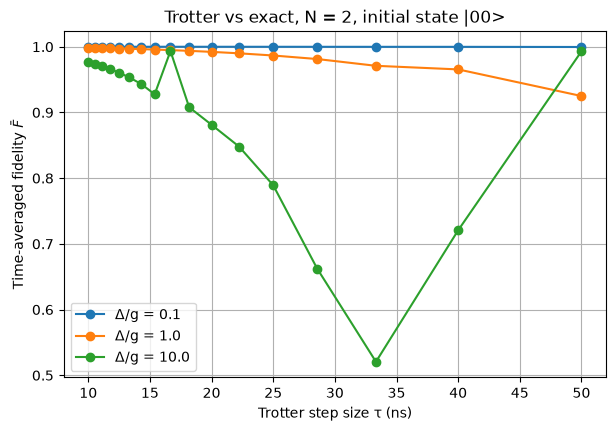

In [101]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for d in delta_j_values:
    taus = np.array([t[-1]/n for n in n_steps]) * 1e3          # ns
    F_avg = np.array([overlap[(d, n)] for n in n_steps])
    ax.plot(taus, F_avg, 'o-', label=f'Δ/g = {d/c:.1f}')

ax.set_xlabel('Trotter step size τ (ns)')
ax.set_ylabel(r'Time-averaged fidelity $\bar F$')
ax.set_title(f'Trotter vs exact, N = {N}, initial state |00>')
ax.legend()
ax.grid()

plt.show()

In [103]:
A

array([[1, 2, 3],
       [0, 1, 2]])